# **DATASET: WINE**

In [220]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition  import PCA
from sklearn.cluster import KMeans
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.metrics import adjusted_rand_score, silhouette_score, confusion_matrix
from scipy.optimize import linear_sum_assignment

sns.set_theme(style="whitegrid", context="notebook")
ORDER = ["Kelas 0", "Kelas 1", "Kelas 2"]
PAL = dict(zip(ORDER, ["#8e1b3a", "#e6a817", "#2a6f97"]))

# 1. **EKSPLORASI DATA**

In [221]:
def analyze_dataset(data_name):
    """Template function untuk analisis dataset"""

    # Load dataset
    if dataset_name == 'diabetes':
      data = datasets.load_diabetes()
      df = pd.DataFrame(data.data, columns=data.feature_names)
      df['target'] = data.target
    elif dataset_name == 'wine':
      data = datasets.load_wine()
      df = pd.DataFrame(data.data, columns=data.feature_names)
      df['target'] = data.target
    elif dataset_name == 'breast_cancer':
      data = datasets.load_breast_cancer()
      df = pd.DataFrame(data.data, columns=data.feature_names)
      df['target'] = data.target
    elif dataset_name == 'titanic':
      df = sns.load_dataset('titanic')

      # Untuk konsistensi, kita set 'survived' sebagai target
      df.rename(columns={'survived': 'target'})

      # Explorasi dasar
    print(f"=== {dataset_name.upper()} DATASET ====")
    print(f"Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")
    print(f"Data Types:\n{df.dtypes}")
    print(f"Missing Values:\n{df.isnull().sum()}")
    print(f"Basic Statistics:")
    print(df.describe())

    return df
dataset_name = 'wine'                        # dataset wine
df = analyze_dataset(dataset_name)           # 13 fitur + kolom 'target'

# Pemisahan fitur & target + label kelas yang mudah dibaca
X = df.drop(columns="target")
y = df["target"]
df["kelas"] = y.map({0: "Kelas 0", 1: "Kelas 1", 2: "Kelas 2"})

print("\nJumlah sampel per kelas:\n", df["kelas"].value_counts().sort_index())
df.head()

=== WINE DATASET ====
Shape: (178, 14)
Columns: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline', 'target']
Data Types:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object
Missing Values:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash           

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,kelas
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,Kelas 0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,Kelas 0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,Kelas 0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,Kelas 0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,Kelas 0


In [222]:
df

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,kelas
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,Kelas 0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,Kelas 0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,Kelas 0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,Kelas 0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,Kelas 0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,2,Kelas 2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0,2,Kelas 2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0,2,Kelas 2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0,2,Kelas 2


In [223]:
# Klasifikasi fitur: numerik vs kategorikal
numerik = X.select_dtypes(include="number").columns.tolist()
print("Fitur numerik:", len(numerik), "->", numerik)
print("Target kategorikal:", ["target / kelas"], "->", y.nunique(), "kelas")


Fitur numerik: 13 -> ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target kategorikal: ['target / kelas'] -> 3 kelas


In [224]:
display(X.describe().round(2).T[["mean", "std", "min", "50%", "max"]])

,mean,std,min,50%,max
alcohol,13.00,0.81,11.03,13.05,14.83
malic_acid,2.34,1.12,0.74,1.87,5.80
ash,2.37,0.27,1.36,2.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,19.50,30.00
magnesium,99.74,14.28,70.00,98.00,162.00
total_phenols,2.30,0.63,0.98,2.36,3.88
flavanoids,2.03,1.00,0.34,2.13,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.34,0.66
proanthocyanins,1.59,0.57,0.41,1.56,3.58
color_intensity,5.06,2.32,1.28,4.69,13.00


In [225]:
# Kolerasi antar fitur
corr = X.corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
              .stack().rename("r").reset_index())
pairs["|r|"] = pairs["r"].abs()
pairs.sort_values("|r|", ascending=False).head(5).round(2)

,level_0,level_1,r,|r|
50,total_phenols,flavanoids,0.86,0.86
61,flavanoids,od280/od315_of_diluted_wines,0.79,0.79
55,total_phenols,od280/od315_of_diluted_wines,0.70,0.70
58,flavanoids,proanthocyanins,0.65,0.65
11,alcohol,proline,0.64,0.64


#2. **Peringkat Fitur Berdasarkan F-Score**

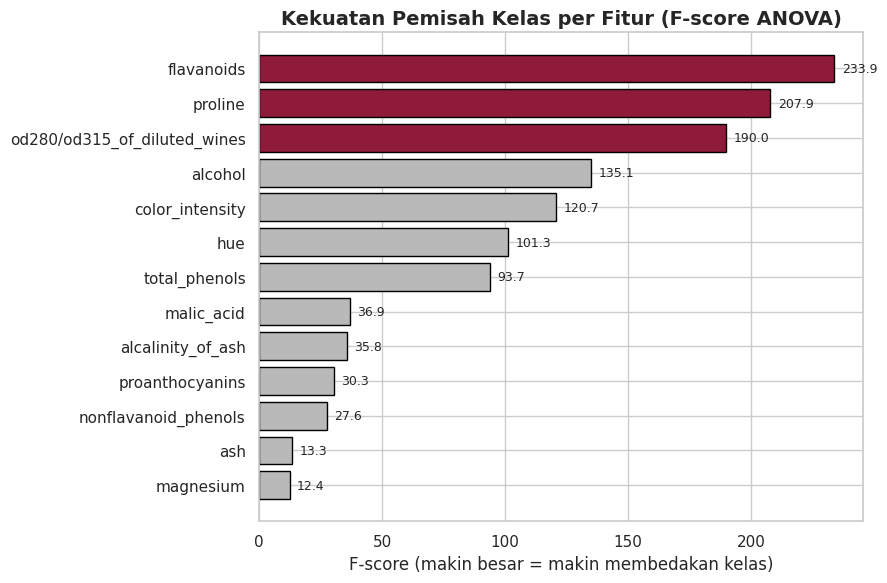

Tiga fitur teratas: flavanoids, proline, od280/od315_of_diluted_wines
p-value terbesar di antara 13 fitur: 9.0e-06  (semua < 0,05)


In [226]:
F, p = f_classif(X, y)
fscore = pd.Series(F, index=X.columns).sort_values(ascending=False)
top6 = fscore.index[:6].tolist()
top3_text = ", ".join(fscore.index[:3])

fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#8e1b3a" if f in fscore.index[:3] else "#b9b9b9" for f in fscore.index]
ax.barh(fscore.index[::-1], fscore.values[::-1], color=colors[::-1], edgecolor="black")
for i, (name, val) in enumerate(zip(fscore.index[::-1], fscore.values[::-1])):
    ax.text(val + 3, i, f"{val:.1f}", va="center", fontsize=9)
ax.set_title("Kekuatan Pemisah Kelas per Fitur (F-score ANOVA)", fontsize=14, fontweight="bold")
ax.set_xlabel("F-score (makin besar = makin membedakan kelas)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()
print("Tiga fitur teratas:", top3_text)
print(f"p-value terbesar di antara 13 fitur: {p.max():.1e}  (semua < 0,05)")

#3.  **Distribusi 6 Fitur Teratas per Kelas**

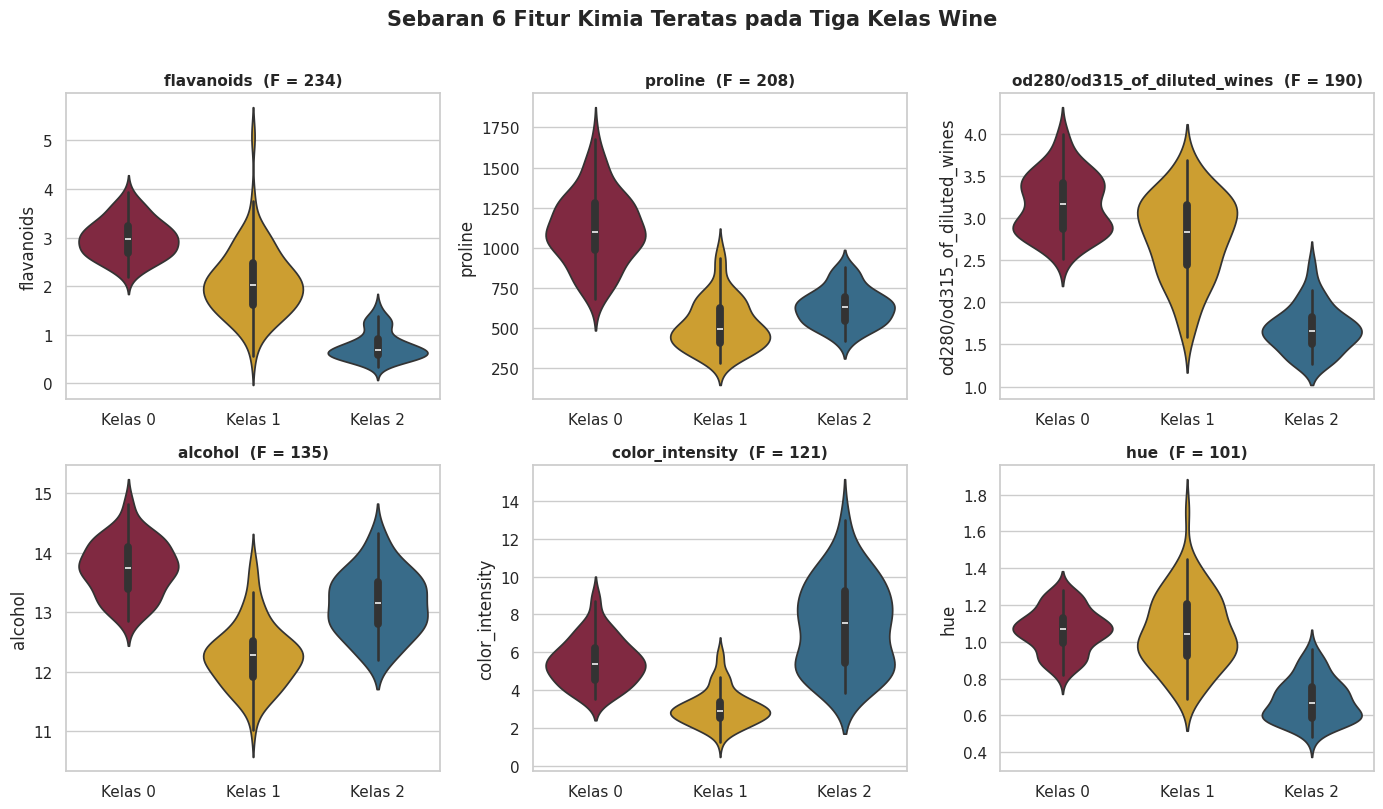

In [227]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, feat in zip(axes.ravel(), top6):
    sns.violinplot(data=df, x="kelas", y=feat, hue="kelas", order=ORDER, hue_order=ORDER,
                   palette=PAL, inner="box", legend=False, ax=ax)
    ax.set_title(f"{feat}  (F = {fscore[feat]:.0f})", fontsize=11, fontweight="bold")
    ax.set_xlabel("")
fig.suptitle("Sebaran 6 Fitur Kimia Teratas pada Tiga Kelas Wine", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

In [228]:
def cohens_d(a, b):
    sp = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1)) / (len(a)+len(b)-2))
    return abs(a.mean() - b.mean()) / sp

rows = []
for feat in X.columns:
    rows.append({
        "fitur": feat,
        "Kelas 0 vs 1": cohens_d(X.loc[y == 0, feat], X.loc[y == 1, feat]),
        "Kelas 0 vs 2": cohens_d(X.loc[y == 0, feat], X.loc[y == 2, feat]),
        "Kelas 1 vs 2": cohens_d(X.loc[y == 1, feat], X.loc[y == 2, feat]),
    })
effect = pd.DataFrame(rows).set_index("fitur").loc[fscore.index].round(2)
display(effect)
print("Rata-rata |d| per pasangan kelas:\n", effect.mean().round(2).to_string())

,Kelas 0 vs 1,Kelas 0 vs 2,Kelas 1 vs 2
flavanoids,1.54,6.20,2.25
proline,3.15,2.67,0.78
od280/od315_of_diluted_wines,0.85,4.58,2.62
alcohol,2.90,1.20,1.64
color_intensity,2.26,1.04,2.64
hue,0.03,3.28,2.16
total_phenols,1.25,3.35,1.21
malic_acid,0.09,1.49,1.34
alcalinity_of_ash,1.06,1.81,0.40
proanthocyanins,0.51,1.82,0.89


Rata-rata |d| per pasangan kelas:
 Kelas 0 vs 1    1.23
Kelas 0 vs 2    2.29
Kelas 1 vs 2    1.36


# 4. **Profil Kimia Tiap Kelas (Heatmap z-score)**

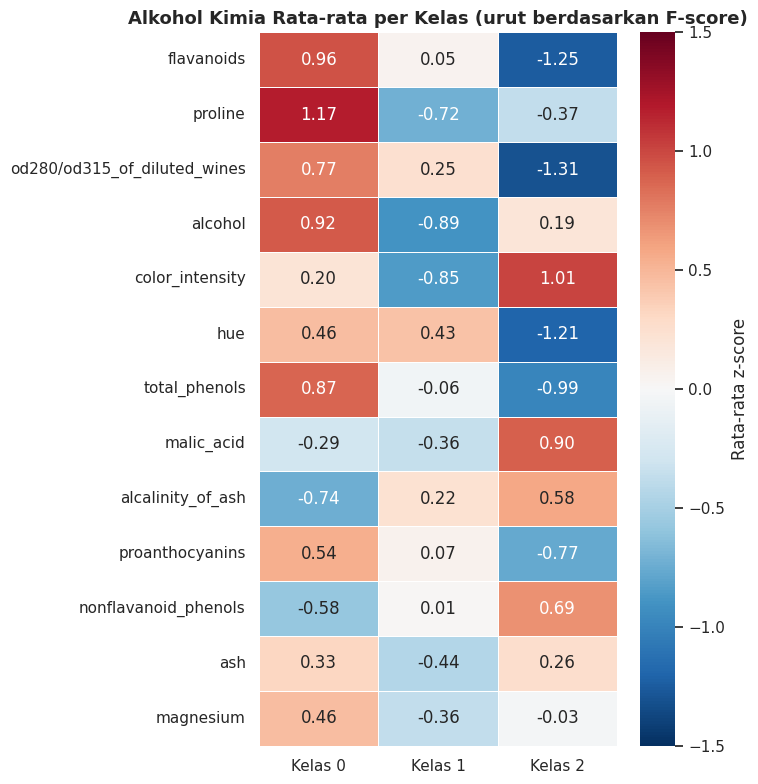

,alcohol,flavanoids,proline,color_intensity,hue,malic_acid
kelas,,,,,,
Kelas 0,13.74,2.98,1115.71,5.53,1.06,2.01
Kelas 1,12.28,2.08,519.51,3.09,1.06,1.93
Kelas 2,13.15,0.78,629.90,7.40,0.68,3.33


In [229]:
Z = StandardScaler().fit_transform(X)
zmeans = (pd.DataFrame(Z, columns=X.columns)
            .groupby(df["kelas"].values).mean()
            .loc[ORDER].T.loc[fscore.index])          # baris diurutkan menurut F-score

fig, ax = plt.subplots(figsize=(7.5, 8))
sns.heatmap(zmeans, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1.5, vmax=1.5,
            linewidths=0.5, cbar_kws={"label": "Rata-rata z-score"}, ax=ax)
ax.set_title("Alkohol Kimia Rata-rata per Kelas (urut berdasarkan F-score)", fontsize=13, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

display(df.groupby("kelas")[["alcohol", "flavanoids", "proline", "color_intensity", "hue", "malic_acid"]].mean().round(2))

#5.  **Proyeksi PCA 2D: Kelas Asli vs Klaster K-Means**

Varians dijelaskan: PC1 = 36.2%, PC2 = 19.2%, total = 55.4%


,PC1,PC2
flavanoids,0.42,-0.00
total_phenols,0.39,0.07
od280/od315_of_diluted_wines,0.38,-0.16
proanthocyanins,0.31,0.04
hue,0.30,-0.28
proline,0.29,0.36
alcohol,0.14,0.48
magnesium,0.14,0.30
ash,-0.00,0.32
color_intensity,-0.09,0.53



Tabel silang kelas asli (baris) vs klaster (kolom, sudah diselaraskan):


klaster,0,1,2
kelas asli,,,
0,59,0,0
1,3,65,3
2,0,0,48


Sampel yang 'salah klaster': 6 dari 178
Adjusted Rand Index = 0.897 | Silhouette = 0.285
Silhouette per k: {2: np.float64(0.259), 3: np.float64(0.285), 4: np.float64(0.26), 5: np.float64(0.202)} -> terbaik k = 3


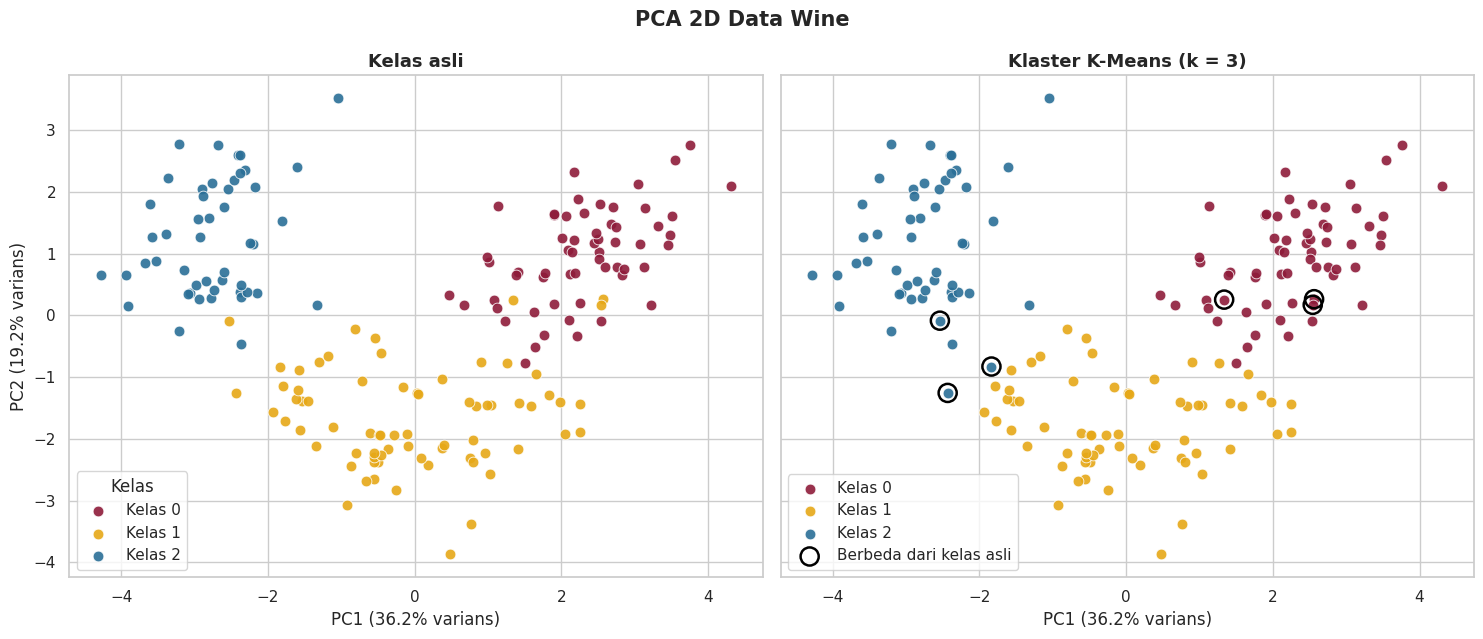

In [230]:
pca = PCA(n_components=2).fit(Z)
P = pca.transform(Z)
evr = pca.explained_variance_ratio_
print(f"Varians dijelaskan: PC1 = {evr[0]:.1%}, PC2 = {evr[1]:.1%}, total = {evr.sum():.1%}")
display(pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"]).round(2)
          .sort_values("PC1", ascending=False))

# --- K-Means (k=3) tanpa label; label klaster diselaraskan ke kelas asli hanya untuk pewarnaan
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Z)
ct = pd.crosstab(y, km.labels_).values
r, c = linear_sum_assignment(-ct)
mapping = {cl: cls for cls, cl in zip(r, c)}
cluster_as_class = pd.Series(km.labels_).map(mapping).values
salah = cluster_as_class != y.values

print("\nTabel silang kelas asli (baris) vs klaster (kolom, sudah diselaraskan):")
display(pd.crosstab(pd.Series(y.values, name="kelas asli"), pd.Series(cluster_as_class, name="klaster")))
print(f"Sampel yang 'salah klaster': {salah.sum()} dari {len(y)}")
print(f"Adjusted Rand Index = {adjusted_rand_score(y, km.labels_):.3f} | Silhouette = {silhouette_score(Z, km.labels_):.3f}")

# Pilihan jumlah klaster: silhouette untuk k = 2..5
sil = {k: silhouette_score(Z, KMeans(k, n_init=10, random_state=42).fit_predict(Z)) for k in range(2, 6)}
print("Silhouette per k:", {k: round(v, 3) for k, v in sil.items()}, "-> terbaik k =", max(sil, key=sil.get))

# --- Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True, sharey=True)
for ax, title, labels in [(axes[0], "Kelas asli", y.values), (axes[1], "Klaster K-Means (k = 3)", cluster_as_class)]:
    for k, name in enumerate(ORDER):
        m = labels == k
        ax.scatter(P[m, 0], P[m, 1], s=60, color=PAL[name], edgecolor="white", linewidth=0.6, label=name, alpha=0.9)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel(f"PC1 ({evr[0]:.1%} varians)")
axes[0].set_ylabel(f"PC2 ({evr[1]:.1%} varians)")
axes[1].scatter(P[salah, 0], P[salah, 1], s=170, facecolors="none", edgecolors="black", linewidths=1.8,
                label="Berbeda dari kelas asli")
axes[0].legend(title="Kelas", loc="best")
axes[1].legend(loc="best")
fig.suptitle("PCA 2D Data Wine", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

In [231]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
pipe = make_pipeline(StandardScaler(), PCA(2), LogisticRegression(max_iter=1000))
print("Akurasi CV (hanya PC1+PC2): %.3f" % cross_val_score(pipe, X, y, cv=cv).mean())
cm = confusion_matrix(y, cross_val_predict(pipe, X, y, cv=cv))
display(pd.DataFrame(cm, index=[f"asli {n}" for n in ORDER], columns=[f"prediksi {n}" for n in ORDER]))

Akurasi CV (hanya PC1+PC2): 0.955


,prediksi Kelas 0,prediksi Kelas 1,prediksi Kelas 2
asli Kelas 0,57,2,0
asli Kelas 1,3,67,1
asli Kelas 2,0,2,46


# 6. **Pair Plot 3 Fitur Non-Redundan**

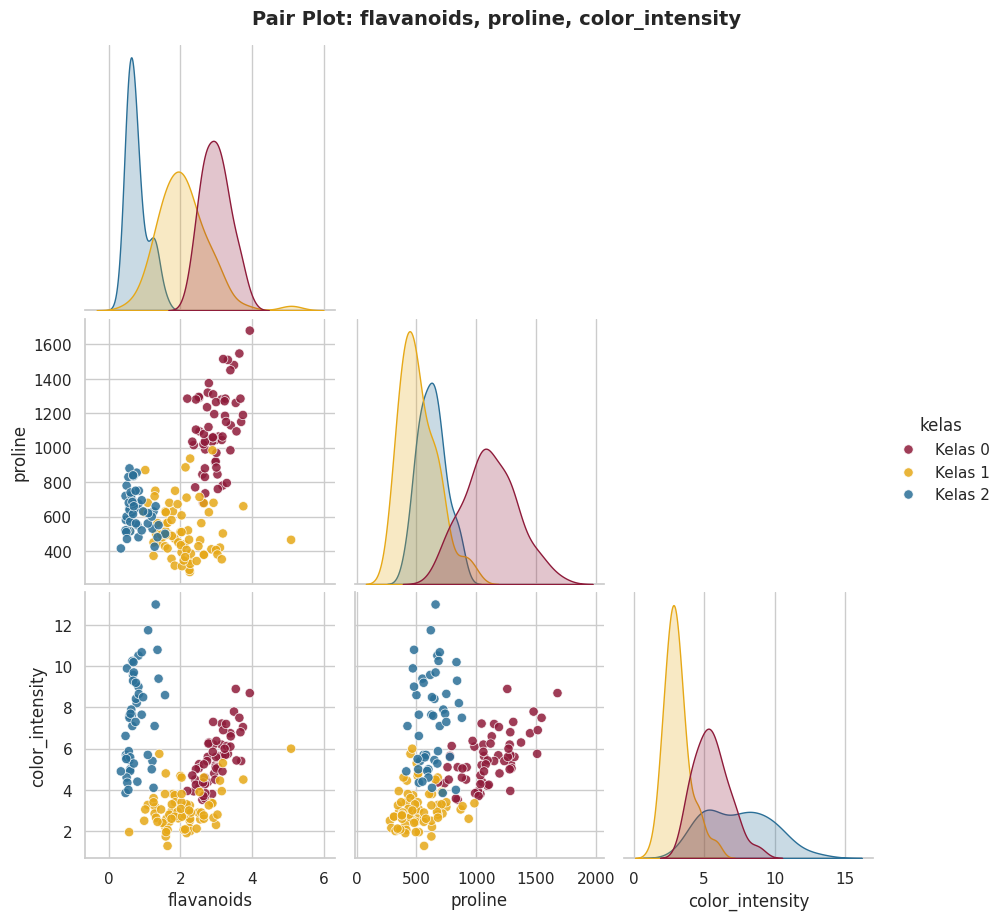

In [232]:
sel = ["flavanoids", "proline", "color_intensity"]
g = sns.pairplot(df, vars=sel, hue="kelas", hue_order=ORDER, palette=PAL,
                 diag_kind="kde", corner=True, height=3.0, plot_kws=dict(s=45, alpha=0.85, edgecolor="white"))
g.figure.suptitle("Pair Plot: flavanoids, proline, color_intensity", y=1.02, fontsize=14, fontweight="bold")
plt.show()

In [233]:
def cv_acc(features):
    mdl = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    return cross_val_score(mdl, X[features], y, cv=cv).mean()

hasil = pd.Series({
    "flavanoids + proline": cv_acc(["flavanoids", "proline"]),
    "flavanoids + color_intensity": cv_acc(["flavanoids", "color_intensity"]),
    "flavanoids + proline + color_intensity": cv_acc(["flavanoids", "proline", "color_intensity"]),
    "semua 13 fitur": cv_acc(X.columns.tolist()),
}, name="akurasi CV").round(3)
hasil.to_frame()

,akurasi CV
flavanoids + proline,0.893
flavanoids + color_intensity,0.904
flavanoids + proline + color_intensity,0.949
semua 13 fitur,0.983


# **DataSet: Wine Anggota Kelompok:**

 1. **Didit Putra Wahyudha_231230016**
 2. **Muhammad Arifin_231230051**
 3. **Bagas Habib Waliyudin_231230035**
 4. **Aldi Eka Saputra_231230049**